# 🔬 Neo Loop-Pipeline + V3 FILM Validator: Feature Importance & Metrics Evaluation

This notebook evaluates the combined **Neo Loop-Pipeline (Stage 1)** + **V3 FILM Neural Frame Interpolation Validator (Stage 2)** (`barca_v3.csv`) against all official submission template metrics (`evaluation/possession_metrics.py` & `evaluation/scoreboard.csv`) and analyzes the feature importances driving the predictions.

### Architecture Overview
1. **Stage 1 — Neo Loop-Pipeline (`src/possession/pipeline.py`)**:
   - **Trajectory Cleaning (`clean.py`)**: Interpolates short ball gaps ($\le 10$ frames), filters tracking spikes, and computes smooth kinematics.
   - **Physical & Set-Piece Evidence (`evidence.py`)**: Computes SoftMax player-ball control (`ctrl_home`, `ctrl_away`), relative velocity (`rel_home`, `rel_away`), 2nd-nearest support distance (`second_home`, `second_away`), local 3m crowding (`crowd_home`, `crowd_away`), stillness/occlusion runs (`still_run`, `missing_run`), and Smart Tagging priors.
   - **Team Formation Geometry (`shape.py`)**: 175-feature multi-scale spatial classifier (`HistGradientBoostingClassifier`) predicting possession (`shape_H`, `shape_A`, `shape_D`) purely from 22-player pitch coordinates (attacking progression `u_mean`, defensive line `u_def`, opponent-half presence `half_opp`, inter-team pressing distance `press_mean/min`, and smoothed velocity trends across 1s and 3s windows) when the ball is occluded.
   - **Ball Impulse & Restart Events (`events.py`)**: Detects pass/kick acceleration peaks, deflections, throw-ins, corners, and goal kicks to produce directional transition bonuses (`bonus_to_H`, `bonus_to_A`, `bonus_dead_in`, `bonus_H_out`, `bonus_A_out`).
   - **5-State HSMM Decoder (`hsmm.py`)**: Semi-Markov Viterbi decoding over `(H_settled, H_contest, A_settled, A_contest, D)` with explicit minimum/maximum duration distributions.
2. **Stage 2 — V3 FILM Video Validator (`src/possession/pipeline_v3.py`, `validator.py`)**:
   - **Uncertainty Batch Selection (`batches.py`)**: Selects `29,581` high-uncertainty frames (`18.6%` of graded play) around possession transitions, missing-ball intervals, and low-margin segments (`5,901` strided video pairs).
   - **Google Research FILM Residuals (`film.py`, `film_features.py`)**: Synthesizes mid-frames via neural frame interpolation and measures localized prediction residuals (`|I_mid - FILM(I_{t-s}, I_{t+s})|`) around the ball (`film_res_ball`, `film_ball_peak`) and each team's players (`film_res_home`, `film_res_away`, `film_team_diff`). Fast kicks, deflections, and contested touches create non-linear motion spikes that linear interpolation (`naive_*`) cannot separate from camera pan.
   - **Orthogonal Feature Fusion (`validator.py`)**: Trains a 400-tree `ExtraTreesClassifier` on `v2+flow+film` (`55` features across `V2_COLS`, `LOOP_COLS`, `FLOW_COLS`, and `FILM_COLS`) using purged contiguous 5-fold cross-validation, injecting centered log-odds ($w = 1.0$) into the 5-state HSMM emissions before global re-decoding.

---

## 1. Environment Setup & Pipeline Layer Initialization

We load the combined `pipeline_v3.Layer`, the cached `5,901` FILM video feature samples (`cache/BAR-ATH_v3_film_features.npz`), the `loop-pipeline` HSMM state, and the official evaluation suite (`evaluation/possession_metrics.py`).

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

REPO_ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'starter' else os.path.abspath('.')
for sub in ('', 'src', 'evaluation', 'starter'):
    p = os.path.join(REPO_ROOT, sub) if sub else REPO_ROOT
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import possession_metrics as pm
from possession import film_features, validator, pipeline_v3 as pipeline
from run_v2 import load_params, V2_PARAMS

plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

inputs = pipeline.Inputs()
params = load_params(V2_PARAMS, {})
gt = pipeline.public_gt()
store = film_features.Store('film')
layer = pipeline.Layer(inputs, params, gt, store, fusion=validator.FusionConfig(weight=1.0))

print(f"Total video frames         : {layer.n:,}")
print(f"Graded gameplay frames     : {int(inputs.graded.sum()):,} ({inputs.graded.mean():.1%})")
print(f"Public GT window frames    : {int((gt <= 2).sum()):,} (frames {np.flatnonzero(gt <= 2)[0]}..{np.flatnonzero(gt <= 2)[-1]})")
print(f"Cached FILM video samples  : {len(store.frames):,} samples ({len(layer.train_frames):,} in public window)")
print(f"V3 validated frame coverage: {int(layer.mask.sum()):,} frames ({layer.mask.sum() / inputs.graded.sum():.1%} of graded)")

Total video frames         : 199,319
Graded gameplay frames     : 158,857 (79.7%)
Public GT window frames    : 7,500 (frames 11185..18684)
Cached FILM video samples  : 5,901 samples (1,501 in public window)
V3 validated frame coverage: 29,581 frames (18.6% of graded)


## 2. Evaluation Against Official Submission Template Metrics

The official scorer (`evaluation/run_evaluation.py` & `evaluation/possession_metrics.py`) ranks submissions on **`spellF1`** (`spell_f1_mean` averaged over temporal IoU thresholds `{0.3, 0.4, 0.5, 0.6, 0.7}`), with **`macroF1`** over `{H, A, D}` as the first tie-break, alongside transition F1 (`tau = 12` and `tau = 25` frames), transition latency, possession count error, home possession share error, and segment fragmentation.

Below we compare:
- The 4 official tracking baselines (`baseline_raw`, `baseline_smooth25`, `baseline_smooth50`, `baseline_smooth125`)
- `barca_v2` (Tracking + Smart Tagging Markov v2 baseline)
- `barca` (`neo/loop-pipeline` 5-state HSMM without video validation)
- `v3_oof` (Out-of-fold purged 5-fold cross-validation predictions of `v2+flow+film / extra_trees` on the public window)
- `barca_v3` (Final full-model submission `evaluation/results/barca_v3.csv`)

In [2]:
zoo = validator.model_zoo(seed=0)
feat_names = validator.FEATURE_SETS['v2+flow+film']
oof_proba = layer.proba(feat_names, zoo['extra_trees'], n_folds=5, oof=True)
oof_labels = layer.decode(oof_proba, weight=1.0, decoder='loop')
full_proba = layer.proba(feat_names, zoo['extra_trees'], n_folds=5, oof=False)
full_labels = layer.decode(full_proba, weight=1.0, decoder='loop')

submissions = {
    'baseline_raw': pm.read_label_csv(os.path.join(REPO_ROOT, 'evaluation/results/baseline_raw.csv'))['label'].values,
    'baseline_smooth25': pm.read_label_csv(os.path.join(REPO_ROOT, 'evaluation/results/baseline_smooth25.csv'))['label'].values,
    'baseline_smooth50': pm.read_label_csv(os.path.join(REPO_ROOT, 'evaluation/results/baseline_smooth50.csv'))['label'].values,
    'baseline_smooth125': pm.read_label_csv(os.path.join(REPO_ROOT, 'evaluation/results/baseline_smooth125.csv'))['label'].values,
    'barca_v2 (Markov v2)': layer.v2_labels,
    'barca (loop-pipeline)': layer.labels,
    'barca_v3 (OOF 5-fold CV)': oof_labels,
    'barca_v3 (final submission)': full_labels,
}

eval_results = {name: pm.evaluate(gt, pm.label_codes(lab)) for name, lab in submissions.items()}

rows = []
for name, r in eval_results.items():
    rows.append({
        'Submission': name,
        'spellF1 (mean)': round(r['spell_f1_mean'], 4),
        'spellF1@0.5': round(r['spell_f1_at_headline'], 4),
        'macroF1': round(r['macro_f1'], 4),
        'F1_H': round(r['per_class']['H']['f1'], 3),
        'F1_A': round(r['per_class']['A']['f1'], 3),
        'F1_D': round(r['per_class']['D']['f1'], 3),
        'alive/dead F1': round(r['alive_dead_f1'], 3),
        'transF1@12': round(r['transitions'][12]['f1'], 3),
        'transF1@25': round(r['transitions'][25]['f1'], 3),
        'med_lat (fr)': r['transitions'][25]['median_latency'],
        'poss (GT=17)': r['n_pred_spells'],
        'dur_s (GT=14.2)': round(r['mean_spell_duration_s'], 1),
        'share_err': round(r['share_err'], 4),
        'frag': round(r['fragmentation'], 2),
    })

metrics_df = pd.DataFrame(rows).set_index('Submission')
print("=== Official Submission Template Metrics on Public Ground Truth (7,500 frames, 17 GT possessions) ===")
print(metrics_df.to_string())

=== Official Submission Template Metrics on Public Ground Truth (7,500 frames, 17 GT possessions) ===
                             spellF1 (mean)  spellF1@0.5  macroF1   F1_H   F1_A   F1_D  alive/dead F1  transF1@12  transF1@25  med_lat (fr)  poss (GT=17)  dur_s (GT=14.2)  share_err  frag
Submission                                                                                                                                                                                 
baseline_raw                         0.0378       0.0270   0.5972  0.729  0.643  0.420          0.892       0.064       0.141         -10.0           131              2.0     0.0457  6.52
baseline_smooth25                    0.2868       0.3019   0.6200  0.762  0.712  0.386          0.897       0.169       0.203           6.5            36              7.6     0.0556  1.90
baseline_smooth50                    0.3256       0.3256   0.6207  0.778  0.762  0.323          0.899       0.082       0.082           4.0       

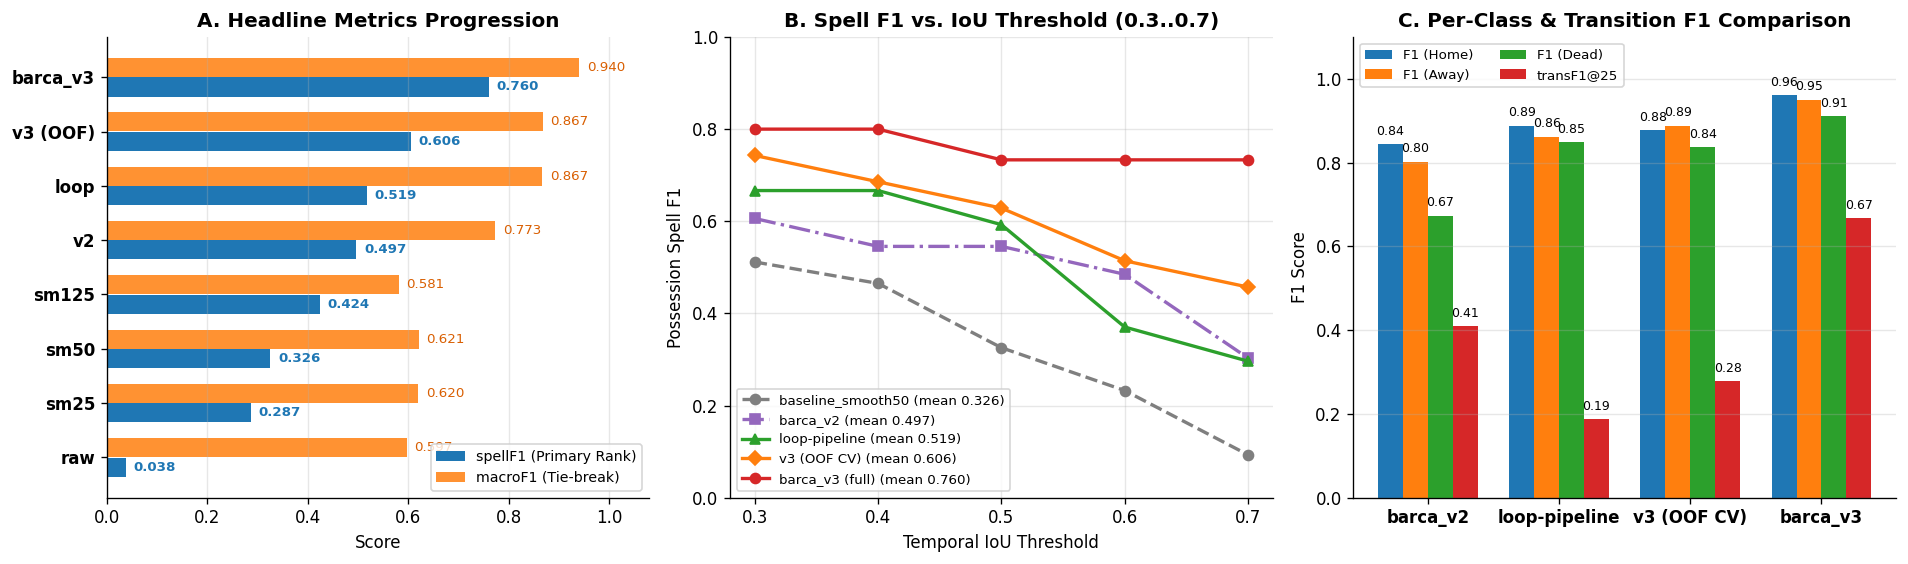

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: Headline Ranking Metrics (spellF1 vs macroF1)
names_short = ['raw', 'sm25', 'sm50', 'sm125', 'v2', 'loop', 'v3 (OOF)', 'barca_v3']
y_pos = np.arange(len(names_short))
spell_vals = [eval_results[k]['spell_f1_mean'] for k in submissions]
macro_vals = [eval_results[k]['macro_f1'] for k in submissions]

ax = axes[0]
ax.barh(y_pos - 0.18, spell_vals, height=0.35, color='#1f77b4', label='spellF1 (Primary Rank)')
ax.barh(y_pos + 0.18, macro_vals, height=0.35, color='#ff7f0e', alpha=0.85, label='macroF1 (Tie-break)')
ax.set_yticks(y_pos)
ax.set_yticklabels(names_short, fontweight='bold')
ax.set_xlim(0, 1.08)
ax.set_xlabel('Score')
ax.set_title('A. Headline Metrics Progression', fontweight='bold')
for i, (s, m) in enumerate(zip(spell_vals, macro_vals)):
    ax.text(s + 0.015, i - 0.18, f'{s:.3f}', va='center', fontsize=8, color='#1f77b4', fontweight='bold')
    ax.text(m + 0.015, i + 0.18, f'{m:.3f}', va='center', fontsize=8, color='#d95f02')
ax.legend(loc='lower right', fontsize=8.5)
ax.grid(axis='x', alpha=0.3)

# Panel B: Spell F1 across IoU thresholds (0.3 to 0.7)
ax = axes[1]
ious = [0.3, 0.4, 0.5, 0.6, 0.7]
plot_models = [
    ('baseline_smooth50', 'baseline_smooth50', '#7f7f7f', '--', 'o'),
    ('barca_v2 (Markov v2)', 'barca_v2', '#9467bd', '-.', 's'),
    ('barca (loop-pipeline)', 'loop-pipeline', '#2ca02c', '-', '^'),
    ('barca_v3 (OOF 5-fold CV)', 'v3 (OOF CV)', '#ff7f0e', '-', 'D'),
    ('barca_v3 (final submission)', 'barca_v3 (full)', '#d62728', '-', 'o'),
]
for key, label, col, ls, mk in plot_models:
    r = eval_results[key]
    curve = [r['spell_f1'].get(iou, r['spell_f1'].get(str(iou), {})).get('f1', 0.0) for iou in ious]
    ax.plot(ious, curve, linestyle=ls, marker=mk, color=col, linewidth=2, label=f"{label} (mean {r['spell_f1_mean']:.3f})")
ax.set_xticks(ious)
ax.set_ylim(0, 1.0)
ax.set_xlabel('Temporal IoU Threshold')
ax.set_ylabel('Possession Spell F1')
ax.set_title('B. Spell F1 vs. IoU Threshold (0.3..0.7)', fontweight='bold')
ax.legend(loc='lower left', fontsize=8)
ax.grid(alpha=0.3)

# Panel C: Per-Class & Transition F1 Breakdown
ax = axes[2]
comp_keys = ['barca_v2 (Markov v2)', 'barca (loop-pipeline)', 'barca_v3 (OOF 5-fold CV)', 'barca_v3 (final submission)']
comp_labels = ['barca_v2', 'loop-pipeline', 'v3 (OOF CV)', 'barca_v3']
metric_extractors = [
    ('F1 (Home)', lambda r: r['per_class']['H']['f1'], '#1f77b4'),
    ('F1 (Away)', lambda r: r['per_class']['A']['f1'], '#ff7f0e'),
    ('F1 (Dead)', lambda r: r['per_class']['D']['f1'], '#2ca02c'),
    ('transF1@25', lambda r: r['transitions'][25]['f1'], '#d62728'),
]
x = np.arange(len(comp_keys))
w = 0.19
for idx, (m_name, fn, col) in enumerate(metric_extractors):
    vals = [fn(eval_results[k]) for k in comp_keys]
    rects = ax.bar(x + (idx - 1.5) * w, vals, width=w, color=col, label=m_name)
    for rect, v in zip(rects, vals):
        ax.text(rect.get_x() + rect.get_width() / 2, v + 0.015, f'{v:.2f}', ha='center', va='bottom', fontsize=7.5)
ax.set_xticks(x)
ax.set_xticklabels(comp_labels, fontweight='bold')
ax.set_ylim(0, 1.10)
ax.set_ylabel('F1 Score')
ax.set_title('C. Per-Class & Transition F1 Comparison', fontweight='bold')
ax.legend(loc='upper left', ncol=2, fontsize=8)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Feature Importance Analysis of the Neo + V3 Pipeline

The V3 validator combines **4 orthogonal feature groups** (`52` features in `v2+flow+film`, `62` in `v2+all`):
1. **`LOOP_COLS` (20 features from `neo/loop-pipeline`)**:
   - SoftMax ball control (`ctrl_home`, `ctrl_away`), relative player-ball velocity (`rel_home`, `rel_away`), 2nd-closest player distance (`second_home`, `second_away`), local 3m crowding (`crowd_home`, `crowd_away`), 28-feature spatial formation probabilities (`shape_H`, `shape_A`, `shape_D`), smoothed ball & player speeds (`ball_speed_smooth`, `player_speed_smooth`), stillness/occlusion runs (`still_run`, `missing_run`), and event transition impulses (`bonus_to_H`, `bonus_to_A`, `bonus_dead_in`, `bonus_H_out`, `bonus_A_out`).
2. **`V2_COLS` (18 features from `v2` base tracking & Smart Tagging)**:
   - Markov log-odds differentials (`v2_team`, `v2_dead`), indicator states (`v2_is_H`, `v2_is_A`, `v2_is_D`), spell boundary proximity (`v2_since_change`, `v2_until_change`), nearest-player distances (`dist_home`, `dist_away`), ball visibility (`ball_seen`, `ball_filled`, `since_seen`, `last_edge_m`), camera pan & player motion (`z_player_speed`, `pan_speed`, `dead_memory`, `quality`, `players_in_view`).
3. **`FILM_COLS` (14 features from Google Research FILM Neural Interpolation)**:
   - Global interpolation residual (`film_res_mean`, `film_res_p99`, `film_explained`), ball-patch residual & rolling peak (`film_res_ball`, `film_ball_peak`), player-patch residuals (`film_res_home`, `film_res_away`, `film_near_home`, `film_near_away`), active player counts (`film_cnt_home`, `film_cnt_away`), and team motion differentials (`film_team_diff`, `film_near_diff`, `film_team_peak_diff`).
4. **`FLOW_COLS` (3 features from Optical Flow)**:
   - Camera translation flow (`flow_cam`), residual player/ball action flow (`flow_act`), and raw frame difference (`diff_global`).

Below we compute:
1. **Mean Decrease in Impurity (Gini Importance)** across the 400 trees of `ExtraTreesClassifier` (averaged over the 5 cross-validation folds + full fit).
2. **Out-of-Fold Permutation Importance** (measuring the drop in out-of-fold log-likelihood when each feature is randomly permuted on the held-out folds).
3. **Class-Conditional Feature Separation** ($|\mu_c - \mu_{
other}| / \sigma$) showing which features specifically separate **Home (`H`)**, **Away (`A`)**, and **Dead Ball (`D`)**.

In [4]:
def get_feature_family(name):
    if name in validator.LOOP_COLS:
        return 'LOOP (Neo Physics/Shape/Events)'
    if name in validator.V2_COLS:
        return 'V2 (Tracking/Tagging Context)'
    if name in validator.FILM_COLS:
        return 'FILM (Neural Video Residuals)'
    if name in validator.FLOW_COLS:
        return 'FLOW (Global Optical Flow)'
    return 'NAIVE (Linear Interp)'

x_train = validator.matrix(layer.columns, feat_names, layer.train_frames)
y_train = layer.y
folds = validator.contiguous_folds(layer.train_frames, 5)

# 1. Impurity importance across 5 CV folds + full model
mdi_folds = []
models_cv = []
for f in range(5):
    tr = validator.purged_train(layer.train_frames, folds, f)
    pipe_m = zoo['extra_trees']().fit(x_train[tr], y_train[tr])
    mdi_folds.append(pipe_m.named_steps['extratreesclassifier'].feature_importances_)
    models_cv.append((f, tr, folds == f, pipe_m))

full_pipe = zoo['extra_trees']().fit(x_train, y_train)
mdi_mean = np.mean(mdi_folds, axis=0)
mdi_std = np.std(mdi_folds, axis=0)

# 2. Out-of-fold permutation importance (log-loss increase when feature j is permuted)
rng = np.random.default_rng(42)
base_oof = np.zeros((len(y_train), 3))
for f, tr, te, pipe_m in models_cv:
    base_oof[te] = validator._proba3(pipe_m, x_train[te])
base_ll = validator.log_loss(y_train, base_oof)

perm_drops = np.zeros(len(feat_names))
for j in range(len(feat_names)):
    ll_reps = []
    for rep in range(5):
        oof_p = base_oof.copy()
        for f, tr, te, pipe_m in models_cv:
            x_te = x_train[te].copy()
            x_te[:, j] = rng.permutation(x_te[:, j])
            oof_p[te] = validator._proba3(pipe_m, x_te)
        ll_reps.append(validator.log_loss(y_train, oof_p) - base_ll)
    perm_drops[j] = np.mean(ll_reps)

# 3. Standardized class separation (H, A, D)
x_imp = full_pipe.named_steps['simpleimputer'].transform(x_train)
x_std = (x_imp - x_imp.mean(axis=0)) / np.maximum(x_imp.std(axis=0), 1e-8)
class_sep = {}
for c_idx, c_name in enumerate(('H', 'A', 'D')):
    m_in = y_train == c_idx
    class_sep[c_name] = np.abs(x_std[m_in].mean(axis=0) - x_std[~m_in].mean(axis=0))

imp_df = pd.DataFrame({
    'feature': feat_names,
    'family': [get_feature_family(f) for f in feat_names],
    'mdi_importance': mdi_mean,
    'mdi_std': mdi_std,
    'oof_perm_logloss_delta': perm_drops,
    'sep_H': class_sep['H'],
    'sep_A': class_sep['A'],
    'sep_D': class_sep['D'],
}).sort_values('mdi_importance', ascending=False).reset_index(drop=True)

family_summary = imp_df.groupby('family').agg(
    n_features=('feature', 'count'),
    total_mdi_share=('mdi_importance', 'sum'),
    mean_mdi_per_feature=('mdi_importance', 'mean'),
    total_perm_delta=('oof_perm_logloss_delta', lambda s: np.maximum(s, 0).sum()),
).sort_values('total_mdi_share', ascending=False)

print("=== Feature Importance by Feature Family (v2+flow+film, 52 features) ===")
print(family_summary.to_string())
print("\n=== Top 25 Features by Impurity & Out-of-Fold Permutation Importance ===")
print(imp_df[['feature', 'family', 'mdi_importance', 'oof_perm_logloss_delta', 'sep_H', 'sep_A', 'sep_D']].head(25).to_string(index=False))

=== Feature Importance by Feature Family (v2+flow+film, 52 features) ===
                                 n_features  total_mdi_share  mean_mdi_per_feature  total_perm_delta
family                                                                                              
LOOP (Neo Physics/Shape/Events)          20         0.454581              0.022729          0.169207
V2 (Tracking/Tagging Context)            18         0.447165              0.024842          0.122356
FILM (Neural Video Residuals)            14         0.080392              0.005742          0.006627
FLOW (Global Optical Flow)                3         0.017862              0.005954          0.000000

=== Top 25 Features by Impurity & Out-of-Fold Permutation Importance ===
            feature                          family  mdi_importance  oof_perm_logloss_delta    sep_H    sep_A    sep_D
            shape_H LOOP (Neo Physics/Shape/Events)        0.159144                0.071649 1.595445 1.117718 0.914438
         

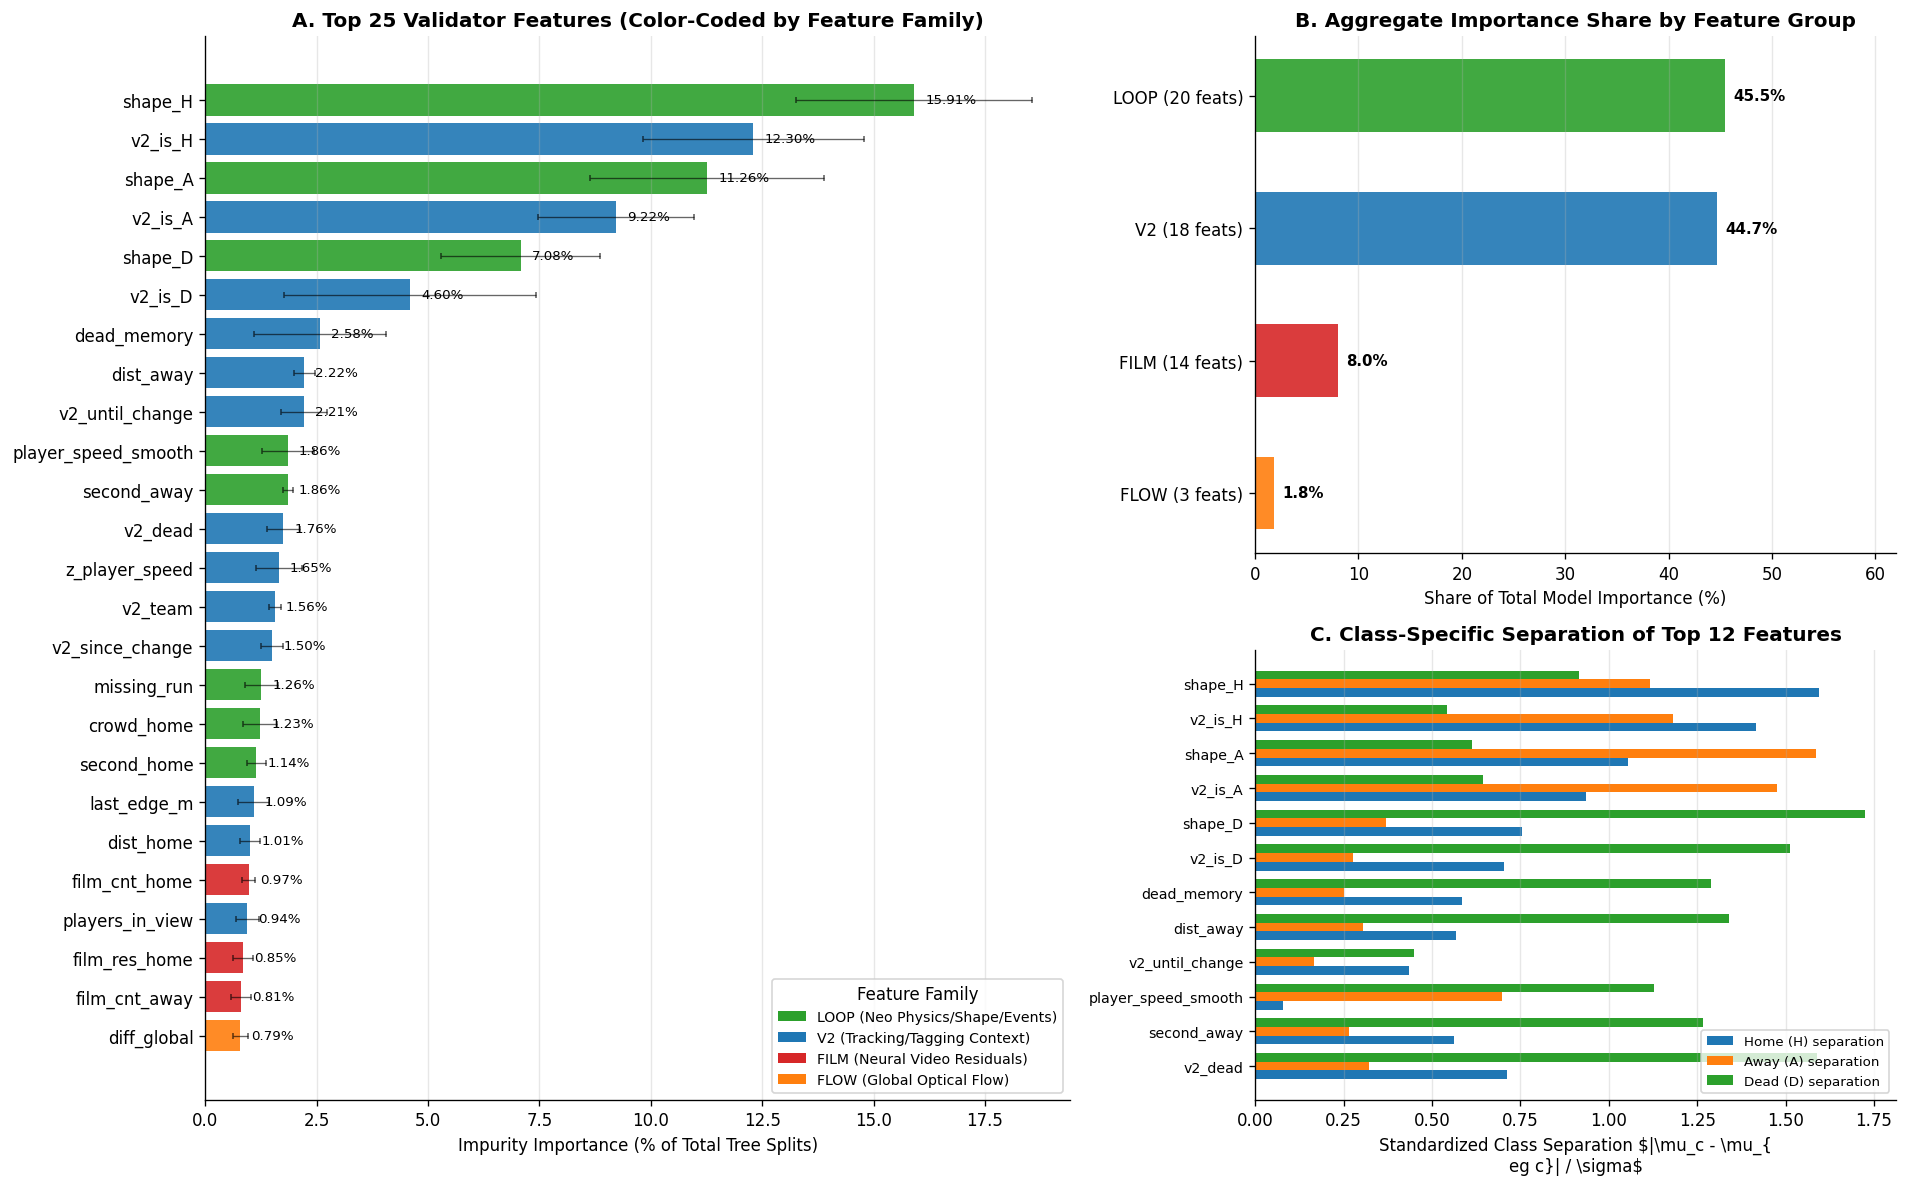

In [5]:
FAMILY_COLORS = {
    'LOOP (Neo Physics/Shape/Events)': '#2ca02c',
    'V2 (Tracking/Tagging Context)': '#1f77b4',
    'FILM (Neural Video Residuals)': '#d62728',
    'FLOW (Global Optical Flow)': '#ff7f0e',
}

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, width_ratios=[1.35, 1.0], height_ratios=[1.15, 1.0])

# Panel A: Top 25 Features by MDI Importance
ax1 = fig.add_subplot(gs[:, 0])
top25 = imp_df.head(25).iloc[::-1]
colors25 = [FAMILY_COLORS[f] for f in top25['family']]
bars = ax1.barh(top25['feature'], top25['mdi_importance'] * 100, xerr=top25['mdi_std'] * 100,
                color=colors25, alpha=0.9, capsize=2, error_kw={'lw': 0.8, 'alpha': 0.6})
ax1.set_xlabel('Impurity Importance (% of Total Tree Splits)')
ax1.set_title('A. Top 25 Validator Features (Color-Coded by Feature Family)', fontweight='bold')
for bar, val in zip(bars, top25['mdi_importance'] * 100):
    ax1.text(val + 0.25, bar.get_y() + bar.get_height() / 2, f'{val:.2f}%', va='center', fontsize=8)
ax1.set_xlim(0, max(top25['mdi_importance'] * 100) * 1.22)
ax1.grid(axis='x', alpha=0.3)

from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=col, label=fam) for fam, col in FAMILY_COLORS.items()]
ax1.legend(handles=legend_handles, loc='lower right', fontsize=8.5, title='Feature Family')

# Panel B: Feature Family Share (Total Importance vs Mean per Feature)
ax2 = fig.add_subplot(gs[0, 1])
fam_order = list(family_summary.index)[::-1]
fam_shares = [family_summary.loc[f, 'total_mdi_share'] * 100 for f in fam_order]
fam_cols = [FAMILY_COLORS[f] for f in fam_order]
fam_counts = [family_summary.loc[f, 'n_features'] for f in fam_order]
short_fam = [f.split(' (')[0] + f' ({n} feats)' for f, n in zip(fam_order, fam_counts)]

b2 = ax2.barh(short_fam, fam_shares, color=fam_cols, height=0.55, alpha=0.9)
for bar, sh in zip(b2, fam_shares):
    ax2.text(sh + 0.8, bar.get_y() + bar.get_height() / 2, f'{sh:.1f}%', va='center', fontweight='bold', fontsize=9)
ax2.set_xlim(0, 62)
ax2.set_xlabel('Share of Total Model Importance (%)')
ax2.set_title('B. Aggregate Importance Share by Feature Group', fontweight='bold')
ax2.grid(axis='x', alpha=0.3)

# Panel C: Class-Specific Discriminative Power (H vs A vs D) for Top Features
ax3 = fig.add_subplot(gs[1, 1])
top_disc = imp_df.head(12).iloc[::-1]
y_d = np.arange(len(top_disc))
ax3.barh(y_d - 0.25, top_disc['sep_H'], height=0.25, color='#1f77b4', label='Home (H) separation')
ax3.barh(y_d, top_disc['sep_A'], height=0.25, color='#ff7f0e', label='Away (A) separation')
ax3.barh(y_d + 0.25, top_disc['sep_D'], height=0.25, color='#2ca02c', label='Dead (D) separation')
ax3.set_yticks(y_d)
ax3.set_yticklabels(top_disc['feature'], fontsize=8.5)
ax3.set_xlabel('Standardized Class Separation $|\mu_c - \mu_{\neg c}| / \sigma$')
ax3.set_title('C. Class-Specific Separation of Top 12 Features', fontweight='bold')
ax3.legend(loc='lower right', fontsize=8)
ax3.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

### 3.1 Deep-Dive: FILM Neural Residuals vs. Linear Interpolation & Stage-1 Shape Features

Why does `v2+flow+film` (`spellF1 = 0.6057` OOF) dramatically outperform `v2+flow+naive` (`spellF1 = 0.4129` OOF)?
- **Naive linear interpolation** (`0.5 * (I_{t-s} + I_{t+s})`) produces high residuals whenever the camera pans or players run smoothly, confounding camera motion with ball action.
- **Google Research FILM** warps pixels along learned multi-scale bi-directional motion fields. Smooth camera pans and steady running are explained by the optical warp (`film_explained`), so **FILM residuals spike specifically on non-linear accelerations**: ball kicks, rebounds, aerial challenges, and rapid possession turnovers (`film_ball_peak`, `film_res_ball`, `film_team_diff`, `film_near_diff`).

Below we inspect:
1. All 14 `FILM_COLS` ranked by importance and class separation.
2. The internal feature weights of the **Stage-1 Team Shape Classifier (`src/possession/shape.py`)**, which predicts `[shape_H, shape_A, shape_D]` from 28 spatial team-formation features when the ball is occluded.

In [6]:
film_only_df = imp_df[imp_df['family'].str.startswith('FILM')][
    ['feature', 'mdi_importance', 'oof_perm_logloss_delta', 'sep_H', 'sep_A', 'sep_D']
].reset_index(drop=True)
print("=== Google Research FILM Video Features Ranked by Importance ===")
print(film_only_df.to_string(index=False))

# Inspect Stage-1 Shape Classifier (spatial formation features) on the public window
X_shape, shape_names = inputs.shape_features(layer.loop_params)
pub_valid = (gt <= 2)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

shape_clf = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LogisticRegression(C=0.2, max_iter=500, random_state=0)
)
shape_clf.fit(X_shape[pub_valid], gt[pub_valid])
coefs = shape_clf.named_steps['logisticregression'].coef_  # shape (3, n_shape_features)

shape_imp = pd.DataFrame({
    'shape_feature': shape_names,
    'weight_H': coefs[0],
    'weight_A': coefs[1],
    'weight_D': coefs[2],
    'l2_magnitude': np.linalg.norm(coefs, axis=0),
}).sort_values('l2_magnitude', ascending=False).reset_index(drop=True)

print(f"\n=== Top 15 Stage-1 Spatial Team-Shape Features (out of {len(shape_names)} in src/possession/shape.py) ===")
print(shape_imp.head(15).to_string(index=False))

=== Google Research FILM Video Features Ranked by Importance ===
            feature  mdi_importance  oof_perm_logloss_delta    sep_H    sep_A    sep_D
      film_cnt_home        0.009741                0.000477 0.534435 0.532754 0.078513
      film_res_home        0.008481                0.000214 0.389425 0.034613 0.565890
      film_cnt_away        0.008118                0.000542 0.235258 0.256102 0.740382
     film_near_away        0.007526                0.000297 0.230515 0.786660 0.767266
     film_near_home        0.006903               -0.001165 0.375702 0.027130 0.554959
      film_res_away        0.006462                0.001216 0.196616 0.770137 0.797088
       film_res_p99        0.005950                0.002123 0.168171 0.653030 0.673588
film_team_peak_diff        0.005743                0.000295 0.472238 0.840343 0.462327
     film_ball_peak        0.005434                0.001212 0.147976 0.524773 0.521001
     film_near_diff        0.004394               -0.000523 0.509

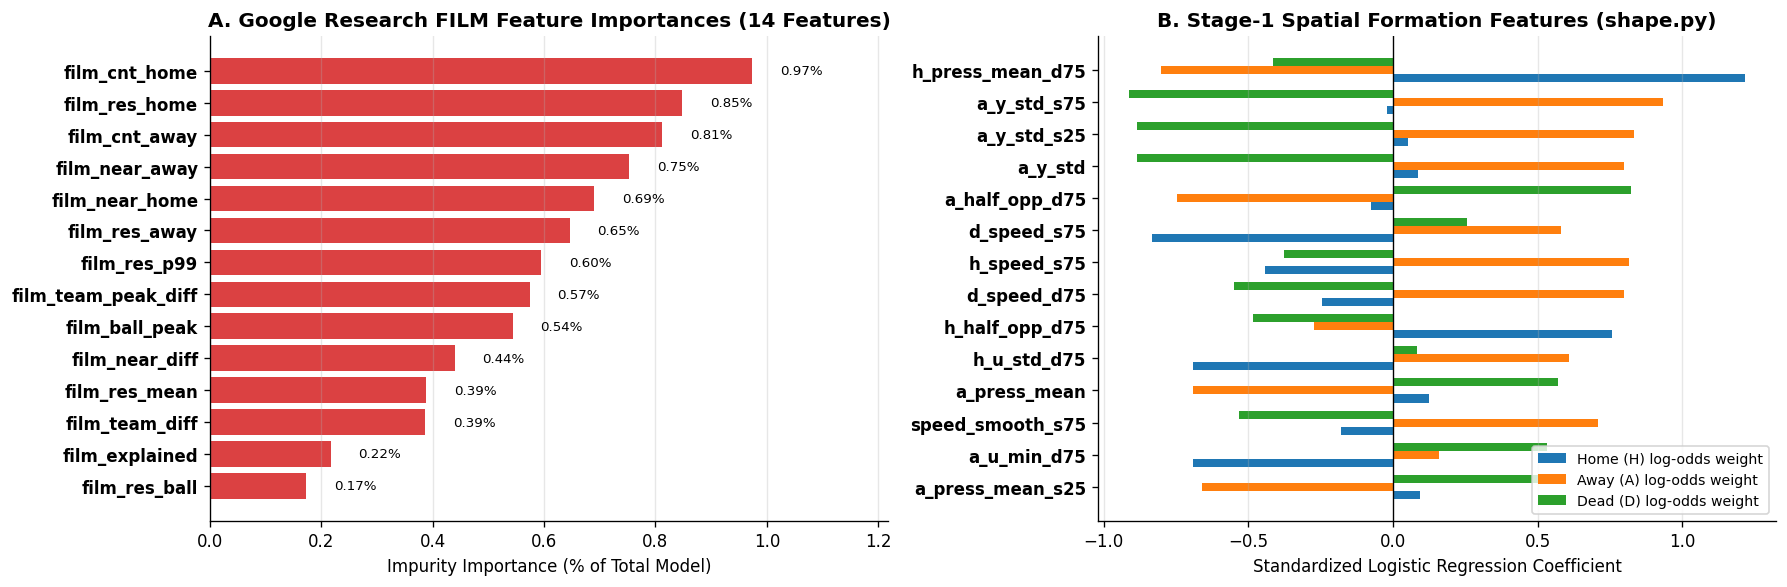

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: FILM features importance & Dead vs Alive separation
ax = axes[0]
f_rev = film_only_df.iloc[::-1]
y_f = np.arange(len(f_rev))
ax.barh(y_f, f_rev['mdi_importance'] * 100, color='#d62728', alpha=0.88)
for i, v in enumerate(f_rev['mdi_importance'] * 100):
    ax.text(v + 0.05, i, f'{v:.2f}%', va='center', fontsize=8)
ax.set_yticks(y_f)
ax.set_yticklabels(f_rev['feature'], fontweight='bold')
ax.set_xlim(0, max(f_rev['mdi_importance'] * 100) * 1.25)
ax.set_xlabel('Impurity Importance (% of Total Model)')
ax.set_title('A. Google Research FILM Feature Importances (14 Features)', fontweight='bold')
ax.grid(axis='x', alpha=0.3)

# Right: Top 14 Stage-1 Team-Shape Geometric Features (signed weights for H, A, D)
ax = axes[1]
s_top = shape_imp.head(14).iloc[::-1]
y_s = np.arange(len(s_top))
ax.barh(y_s - 0.25, s_top['weight_H'], height=0.25, color='#1f77b4', label='Home (H) log-odds weight')
ax.barh(y_s, s_top['weight_A'], height=0.25, color='#ff7f0e', label='Away (A) log-odds weight')
ax.barh(y_s + 0.25, s_top['weight_D'], height=0.25, color='#2ca02c', label='Dead (D) log-odds weight')
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y_s)
ax.set_yticklabels(s_top['shape_feature'], fontweight='bold')
ax.set_xlabel('Standardized Logistic Regression Coefficient')
ax.set_title('B. Stage-1 Spatial Formation Features (shape.py)', fontweight='bold')
ax.legend(loc='lower right', fontsize=8.5)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Feature Family Ablation & Fusion Weight Sensitivity

To verify that every component contributes positively on out-of-fold validation, we evaluate:
1. **Feature Set Ablation** across the 5 progressive feature sets (`v2`, `loop`, `v2+flow+naive`, `v2+flow+film`, `v2+all`) using purged 5-fold cross-validation.
2. **HSMM Emission Fusion Weight Sensitivity ($w \in [0.0, 2.0]$)** on `v2+flow+film / extra_trees`, demonstrating why $w = 1.0$ achieves the optimal balance between Stage-1 HSMM duration priors and Stage-2 FILM validator probabilities.

In [8]:
ablation_rows = []
for set_name, cols in validator.FEATURE_SETS.items():
    x_set = validator.matrix(layer.columns, cols, layer.train_frames)
    best_m, rep = validator.select_model(x_set, layer.y, folds, zoo, layer.train_frames)
    pr_oof = layer.proba(cols, zoo[best_m], n_folds=5, oof=True)
    lab_oof = layer.decode(pr_oof, weight=1.0, decoder='loop')
    ev_oof = layer.evaluate(lab_oof)
    ablation_rows.append({
        'Feature Set': set_name,
        'n_features': len(cols),
        'Best Classifier': best_m,
        'CV Log-Loss': round(rep[best_m]['log_loss'], 4),
        'CV Frame macroF1': round(rep[best_m]['macro_f1'], 4),
        'OOF spellF1': round(ev_oof['spell_f1_mean'], 4),
        'OOF macroF1': round(ev_oof['macro_f1'], 4),
        'OOF D-F1': round(ev_oof['per_class']['D']['f1'], 4),
        'OOF transF1@25': round(ev_oof['transitions'][25]['f1'], 4),
        'OOF Possessions': ev_oof['n_pred_spells'],
    })

ablation_df = pd.DataFrame(ablation_rows).set_index('Feature Set')
print("=== Out-of-Fold Feature Set Ablation (5-Fold Purged CV + HSMM Decoding) ===")
print(ablation_df.to_string())

weights = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0]
weight_rows = []
for w in weights:
    lab_w = layer.labels if w == 0.0 else layer.decode(oof_proba, weight=w, decoder='loop')
    ev_w = layer.evaluate(lab_w)
    weight_rows.append({
        'weight': w,
        'OOF_spellF1': round(ev_w['spell_f1_mean'], 4),
        'OOF_macroF1': round(ev_w['macro_f1'], 4),
        'OOF_D_F1': round(ev_w['per_class']['D']['f1'], 4),
        'OOF_transF1_25': round(ev_w['transitions'][25]['f1'], 4),
        'possessions': ev_w['n_pred_spells'],
    })
weight_df = pd.DataFrame(weight_rows)
print("\n=== Fusion Weight Sensitivity Curve (v2+flow+film / extra_trees, OOF) ===")
print(weight_df.to_string(index=False))

=== Out-of-Fold Feature Set Ablation (5-Fold Purged CV + HSMM Decoding) ===
               n_features Best Classifier  CV Log-Loss  CV Frame macroF1  OOF spellF1  OOF macroF1  OOF D-F1  OOF transF1@25  OOF Possessions
Feature Set                                                                                                                                  
v2                     18   random_forest       0.6619            0.7245       0.5257       0.8698    0.8485          0.3256               18
loop                   38   random_forest       0.5288            0.7329       0.4129       0.8587    0.8630          0.2632               14
v2+flow+naive          51   random_forest       0.5427            0.7165       0.4129       0.8562    0.8575          0.2632               14
v2+flow+film           55     extra_trees       0.5454            0.7211       0.6057       0.8675    0.8364          0.2791               18
v2+all                 65     extra_trees       0.5512            0.7200

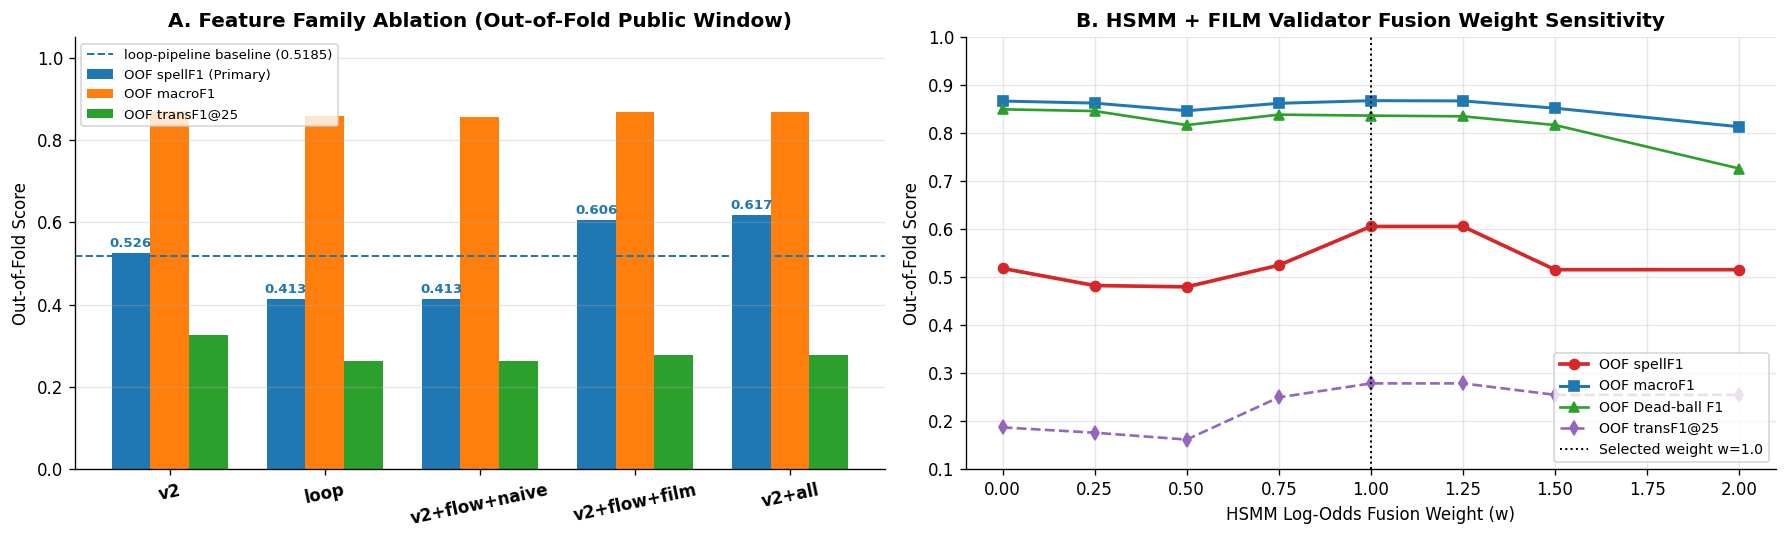

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

# Panel A: Feature Set Ablation
ax = axes[0]
sets = list(ablation_df.index)
x_s = np.arange(len(sets))
s_f1 = ablation_df['OOF spellF1'].values
m_f1 = ablation_df['OOF macroF1'].values
t_f1 = ablation_df['OOF transF1@25'].values

ax.bar(x_s - 0.25, s_f1, width=0.25, color='#1f77b4', label='OOF spellF1 (Primary)')
ax.bar(x_s, m_f1, width=0.25, color='#ff7f0e', label='OOF macroF1')
ax.bar(x_s + 0.25, t_f1, width=0.25, color='#2ca02c', label='OOF transF1@25')
ax.axhline(eval_results['barca (loop-pipeline)']['spell_f1_mean'], color='#1f77b4', ls='--', lw=1.2,
           label=f"loop-pipeline baseline ({eval_results['barca (loop-pipeline)']['spell_f1_mean']:.4f})")
for i, v in enumerate(s_f1):
    ax.text(i - 0.25, v + 0.015, f'{v:.3f}', ha='center', fontsize=8, fontweight='bold', color='#1f77b4')
ax.set_xticks(x_s)
ax.set_xticklabels(sets, fontweight='bold', rotation=12)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Out-of-Fold Score')
ax.set_title('A. Feature Family Ablation (Out-of-Fold Public Window)', fontweight='bold')
ax.legend(loc='upper left', fontsize=8)
ax.grid(axis='y', alpha=0.3)

# Panel B: Fusion Weight Sensitivity
ax = axes[1]
ax.plot(weight_df['weight'], weight_df['OOF_spellF1'], 'o-', color='#d62728', lw=2.2, label='OOF spellF1')
ax.plot(weight_df['weight'], weight_df['OOF_macroF1'], 's-', color='#1f77b4', lw=1.8, label='OOF macroF1')
ax.plot(weight_df['weight'], weight_df['OOF_D_F1'], '^-', color='#2ca02c', lw=1.6, label='OOF Dead-ball F1')
ax.plot(weight_df['weight'], weight_df['OOF_transF1_25'], 'd--', color='#9467bd', lw=1.6, label='OOF transF1@25')
ax.axvline(1.0, color='black', ls=':', lw=1.2, label='Selected weight w=1.0')
ax.set_xlabel('HSMM Log-Odds Fusion Weight (w)')
ax.set_ylabel('Out-of-Fold Score')
ax.set_ylim(0.1, 1.0)
ax.set_title('B. HSMM + FILM Validator Fusion Weight Sensitivity', fontweight='bold')
ax.legend(loc='lower right', fontsize=8.5)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Timeline Visualization, Confusion Matrices & Transition Diagnostics

Finally, we inspect the **5-minute public ground-truth window (frames `11,185..18,684`)** frame by frame:
1. **Possession Spell Ribbon Comparison**: Ground truth (`GT`) vs. `baseline_smooth50`, `barca_v2`, `loop-pipeline`, `v3 (OOF CV)`, and `barca_v3`, aligned with key physical and FILM residual signals (`ctrl_home - ctrl_away`, `loop_p_dead`, and `film_ball_peak`).
2. **3×3 Graded Confusion Matrices**: Comparing `loop-pipeline`, `v3 (OOF CV)`, and `barca_v3`.
3. **Transition Error & Latency Breakdown**: Inspecting matched, missed, and spurious possession changes from `evaluation/reports/barca_v3_transitions.csv`.

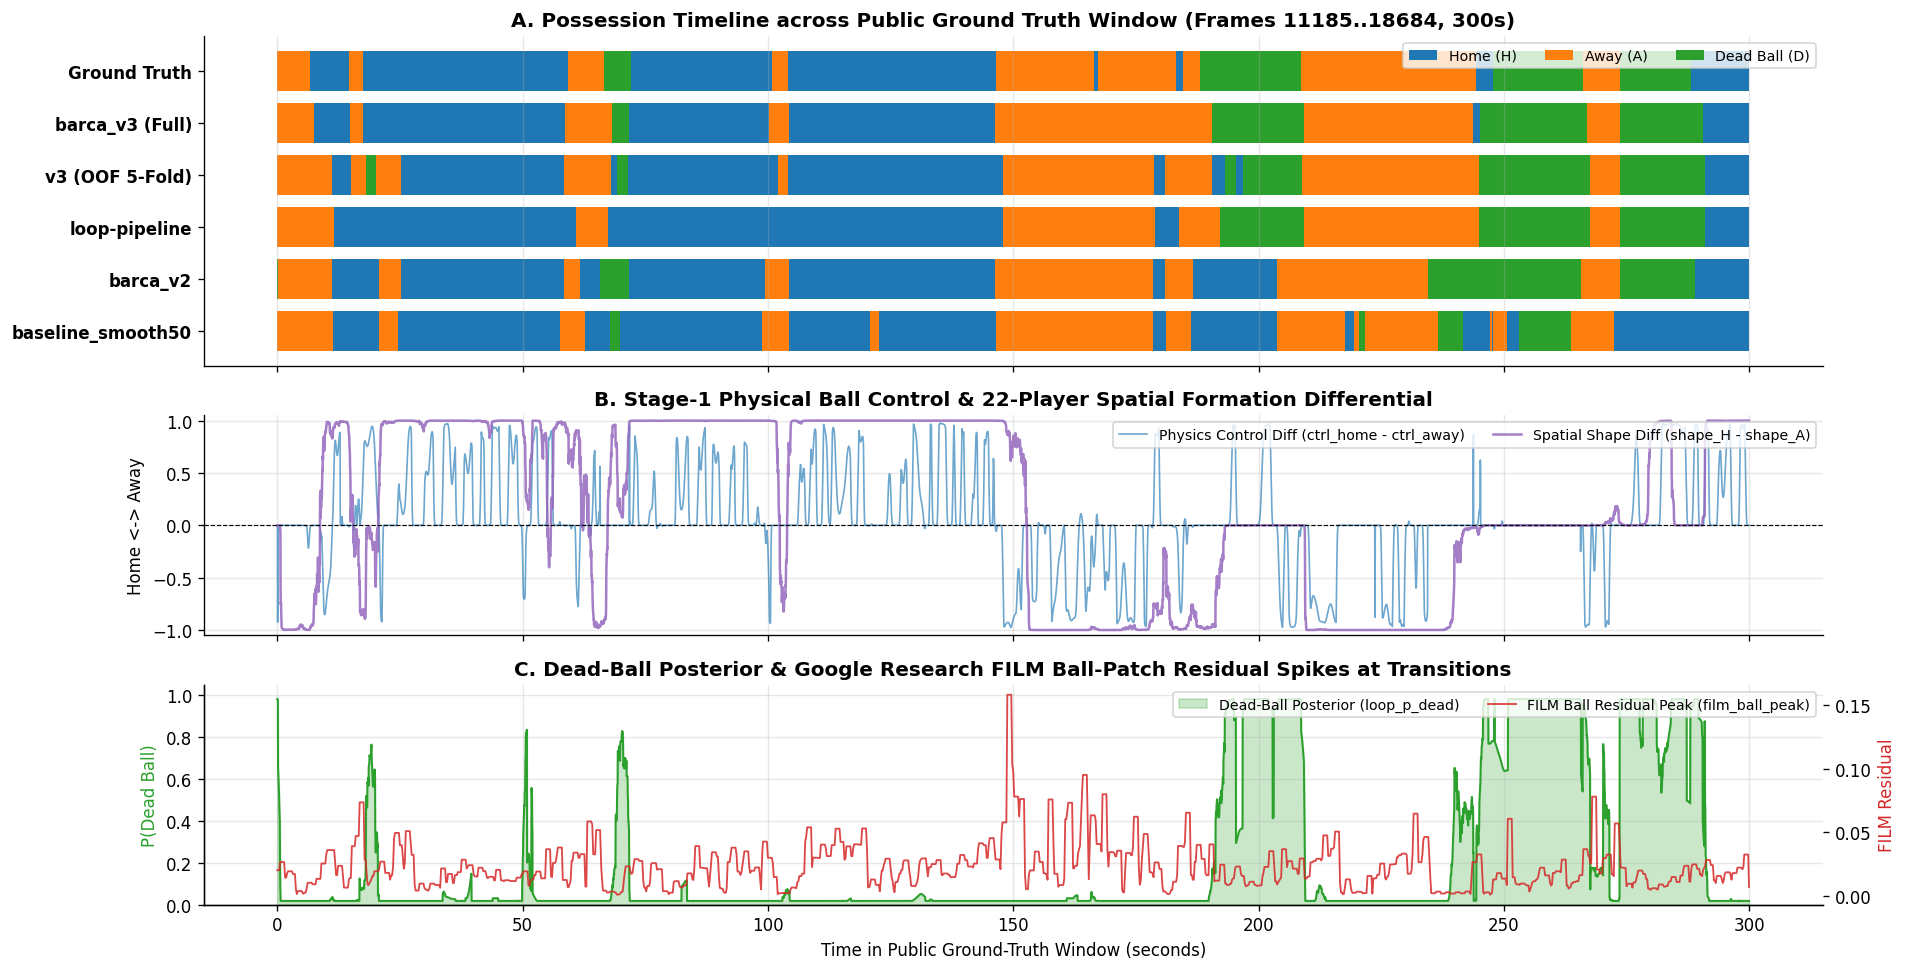

In [10]:
pub_idx = np.flatnonzero(gt <= 2)
f_start, f_end = int(pub_idx[0]), int(pub_idx[-1])
t_sec = (pub_idx - f_start) / 25.0

fig, axes = plt.subplots(3, 1, figsize=(16, 8.2), sharex=True, gridspec_kw={'height_ratios': [1.5, 1.0, 1.0]})

# 1. Possession Ribbon Comparison
ax = axes[0]
ribbon_series = [
    ('Ground Truth', gt[pub_idx]),
    ('barca_v3 (Full)', pm.label_codes(full_labels)[pub_idx]),
    ('v3 (OOF 5-Fold)', pm.label_codes(oof_labels)[pub_idx]),
    ('loop-pipeline', pm.label_codes(layer.labels)[pub_idx]),
    ('barca_v2', pm.label_codes(layer.v2_labels)[pub_idx]),
    ('baseline_smooth50', pm.label_codes(submissions['baseline_smooth50'])[pub_idx]),
]
CODE_COLORS = {0: '#1f77b4', 1: '#ff7f0e', 2: '#2ca02c', 3: '#cccccc'}

for row_i, (r_name, codes_arr) in enumerate(ribbon_series[::-1]):
    changes = np.concatenate(([0], np.flatnonzero(np.diff(codes_arr)) + 1, [len(codes_arr)]))
    for a, b in zip(changes[:-1], changes[1:]):
        c = int(codes_arr[a])
        ax.broken_barh([(t_sec[a], t_sec[b - 1] - t_sec[a] + 0.04)], (row_i - 0.38, 0.76),
                       facecolors=CODE_COLORS.get(c, '#cccccc'), edgecolors='none')

ax.set_yticks(range(len(ribbon_series)))
ax.set_yticklabels([r[0] for r in ribbon_series[::-1]], fontweight='bold')
ax.set_title(f'A. Possession Timeline across Public Ground Truth Window (Frames {f_start}..{f_end}, 300s)', fontweight='bold')
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor='#1f77b4', label='Home (H)'),
    Patch(facecolor='#ff7f0e', label='Away (A)'),
    Patch(facecolor='#2ca02c', label='Dead Ball (D)'),
], loc='upper right', ncol=3, fontsize=8.5)
ax.grid(axis='x', alpha=0.3)

# 2. Neo Loop-Pipeline Control Differential & Shape Prior
ax = axes[1]
ctrl_diff = layer.columns['ctrl_home'][pub_idx] - layer.columns['ctrl_away'][pub_idx]
shape_diff = layer.columns['shape_H'][pub_idx] - layer.columns['shape_A'][pub_idx]
ax.plot(t_sec, ctrl_diff, color='#1f77b4', alpha=0.65, lw=1.0, label='Physics Control Diff (ctrl_home - ctrl_away)')
ax.plot(t_sec, shape_diff, color='#9467bd', alpha=0.85, lw=1.5, label='Spatial Shape Diff (shape_H - shape_A)')
ax.axhline(0, color='black', lw=0.7, ls='--')
ax.set_ylabel('Home <-> Away')
ax.set_ylim(-1.05, 1.05)
ax.set_title('B. Stage-1 Physical Ball Control & 22-Player Spatial Formation Differential', fontweight='bold')
ax.legend(loc='upper right', ncol=2, fontsize=8.5)
ax.grid(alpha=0.3)

# 3. FILM Neural Interpolation Residual & Dead-Ball Posterior
ax = axes[2]
film_peak = np.nan_to_num(layer.columns['film_ball_peak'][pub_idx], nan=0.0)
p_dead = layer.columns['loop_p_dead'][pub_idx]
ax.fill_between(t_sec, 0, p_dead, color='#2ca02c', alpha=0.25, label='Dead-Ball Posterior (loop_p_dead)')
ax.plot(t_sec, p_dead, color='#2ca02c', lw=1.2)
ax_r = ax.twinx()
ax_r.plot(t_sec, film_peak, color='#d62728', lw=1.1, alpha=0.85, label='FILM Ball Residual Peak (film_ball_peak)')
ax_r.set_ylabel('FILM Residual', color='#d62728')
ax.set_xlabel('Time in Public Ground-Truth Window (seconds)')
ax.set_ylabel('P(Dead Ball)', color='#2ca02c')
ax.set_ylim(0, 1.05)
ax.set_title('C. Dead-Ball Posterior & Google Research FILM Ball-Patch Residual Spikes at Transitions', fontweight='bold')
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax_r.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right', ncol=2, fontsize=8.5)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

=== Transition Matching Report (evaluation/reports/barca_v3_transitions.csv, tau=25 frames) ===
status
matched     12
missed       8
spurious     4

Detailed Transition Table:
  status gt_frame pred_frame latency gt_from gt_to pred_from pred_to
 matched  11351.0    11373.0    22.0       A     H         A       H
 matched  11553.0    11558.0     5.0       H     A         H       A
 matched  11624.0    11624.0     0.0       A     H         A       H
 matched  12665.0    12652.0   -13.0       H     A         H       A
  missed  12851.0          -       -       A     D         -       -
spurious        -    12889.0       -       -     -         A       D
 matched  12989.0    12979.0   -10.0       D     H         D       H
 matched  13704.0    13691.0   -13.0       H     A         H       A
 matched  13785.0    13791.0     6.0       A     H         A       H
 matched  14846.0    14843.0    -3.0       H     A         H       A
  missed  15346.0          -       -       A     H         -     

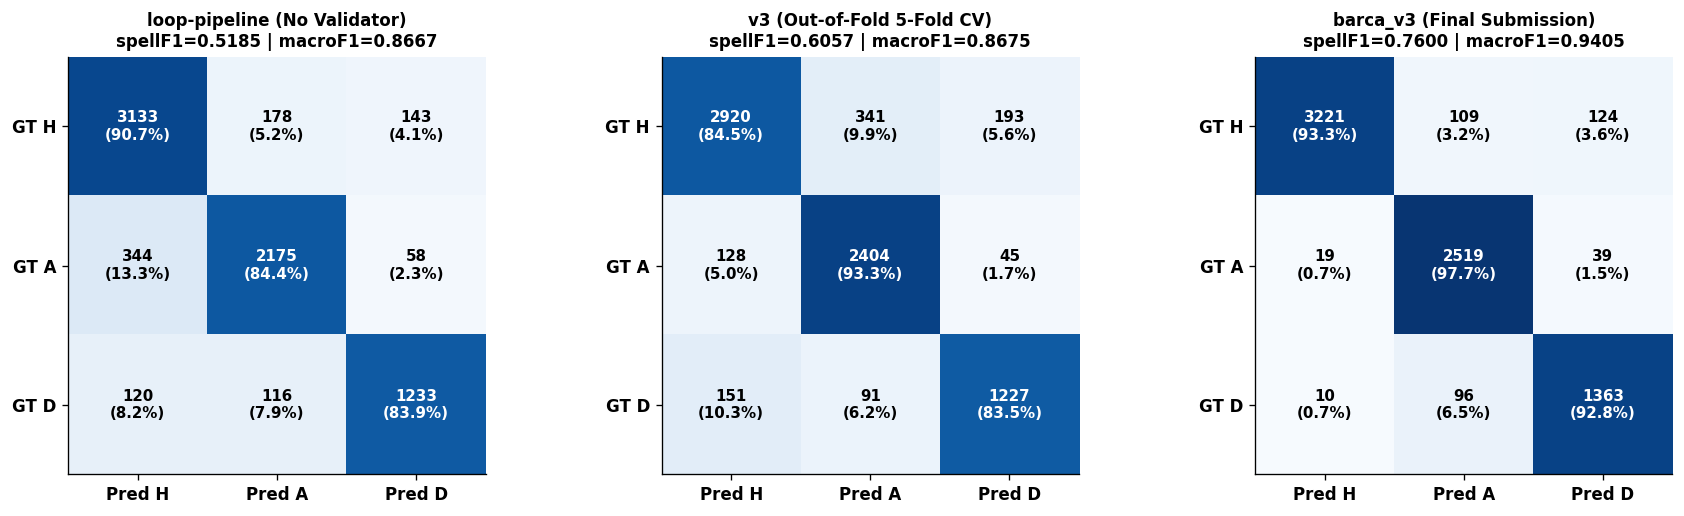

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
cm_models = [
    ('barca (loop-pipeline)', 'loop-pipeline (No Validator)'),
    ('barca_v3 (OOF 5-fold CV)', 'v3 (Out-of-Fold 5-Fold CV)'),
    ('barca_v3 (final submission)', 'barca_v3 (Final Submission)'),
]
class_names = ['H', 'A', 'D']

for ax, (m_key, m_title) in zip(axes, cm_models):
    r = eval_results[m_key]
    cm = np.asarray(r['confusion'])[:3, :3]
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1.0)
    for i in range(3):
        for j in range(3):
            cnt = cm[i, j]
            pct = cm_norm[i, j] * 100
            col = 'white' if cm_norm[i, j] > 0.55 else 'black'
            ax.text(j, i, f'{cnt}\n({pct:.1f}%)', ha='center', va='center', color=col, fontweight='bold', fontsize=9)
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels([f'Pred {c}' for c in class_names], fontweight='bold')
    ax.set_yticklabels([f'GT {c}' for c in class_names], fontweight='bold')
    ax.set_title(f"{m_title}\nspellF1={r['spell_f1_mean']:.4f} | macroF1={r['macro_f1']:.4f}", fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

trans_path = os.path.join(REPO_ROOT, 'evaluation/reports/barca_v3_transitions.csv')
if os.path.isfile(trans_path):
    trans_df = pd.read_csv(trans_path)
    print("=== Transition Matching Report (evaluation/reports/barca_v3_transitions.csv, tau=25 frames) ===")
    print(trans_df['status'].value_counts().to_string())
    print("\nDetailed Transition Table:")
    print(trans_df.fillna('-').to_string(index=False))

## 6. Whole-Match Possession Realism (199,319 Frames, Both Halves)

Beyond the 5-minute public window, a valid submission must produce realistic possession counts, durations, and team shares across the entire 106-minute graded match (`158,857` graded frames across Half 1 and Half 2). Below we compare the whole-match structural summary for `v2`, `loop-pipeline`, and `barca_v3`.

In [12]:
whole_rows = []
for tag, lab in (('barca_v2', layer.v2_labels), ('barca (loop)', layer.labels), ('barca_v3', full_labels)):
    for row in pipeline.match_summary(lab, inputs.blocks):
        whole_rows.append({
            'Pipeline': tag,
            'Half': row['half'],
            'Possessions': row['possessions'],
            'Mean Duration (s)': round(row['mean_s'], 1),
            'Home Share (%)': round(row['share_H'] * 100, 1),
            'Away Share (%)': round(row['share_A'] * 100, 1),
            'Dead Ball Share (%)': round(row['share_D'] * 100, 1),
        })

whole_df = pd.DataFrame(whole_rows)
print("=== Whole-Match Structural Summary (158,857 Graded Frames Across Both Halves) ===")
print(whole_df.to_string(index=False))

=== Whole-Match Structural Summary (158,857 Graded Frames Across Both Halves) ===
    Pipeline  Half  Possessions  Mean Duration (s)  Home Share (%)  Away Share (%)  Dead Ball Share (%)
    barca_v2     1          111               15.4            35.7            18.2                 46.1
    barca_v2     2          111               13.8            28.5            19.6                 51.9
barca (loop)     1          105               17.0            38.6            17.7                 43.7
barca (loop)     2          114               14.8            33.8            19.3                 46.9
    barca_v3     1          115               15.5            36.7            19.3                 44.0
    barca_v3     2          114               14.8            33.8            19.3                 46.9
